# HappyCity Gen : démonstration

Scénarios d'**espaces verts** sur des tuiles de 1 024 m × 1 024 m (8 m/px) à Marrakech.
Un modèle génératif conditionnel propose où créer de nouveaux espaces verts, sur les seules
parcelles autorisées (R), sous un **budget b**, en visant une **cible a** d'accessibilité.

Chaque proposition est chiffrée par le module de métriques **indépendant** :
- **A400** : part des habitations à ≤ 400 m d'un espace vert, en distance **réseau** piéton
  (Dijkstra) ;
- **E** : équité entre secteurs de la tuile, toujours lue **avec** A400 ;
- **V** : couverture végétale.

Ce notebook, la commande `happycity demo` et l'interface Streamlit (`happycity demo --ui`)
appellent les **mêmes fonctions** (`happycity.demo`).

In [1]:
import os
from pathlib import Path

os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
import pandas as pd
from happycity import demo
from happycity.config import load_config

pd.set_option("display.precision", 3)
cfg = load_config()
print(demo.DISCLAIMER)

Scénarios exploratoires : les indicateurs mesurent l'accès piéton à 400 m (distance réseau) et la végétation, pas le bien-être des habitants. Les propositions ne sont pas des projets urbains : elles ignorent le foncier, les coûts et la concertation.


## 1. Tuiles et modèles disponibles

In [2]:
tiles = demo.available_tiles(cfg)
runs = demo.available_runs(cfg)
model = demo.default_run(runs)
print(len(tiles), "tuiles ;", len(runs), "modèles ; modèle par défaut :", model.name)
tiles[tiles["split"] == "test"][["tile_id", "zone", "A400_before", "E_before", "capacity_px",
                                 "greedy_0.01", "greedy_0.02", "greedy_0.05"]]

624 tuiles ; 13 modèles ; modèle par défaut : C-full-s42


,tile_id,zone,A400_before,E_before,capacity_px,greedy_0.01,greedy_0.02,greedy_0.05
0,gueliz_00,gueliz,0.462,0.174,85,0.797,0.797,0.797
104,gueliz_01,gueliz,0.170,0.416,57,0.464,0.464,0.464
208,gueliz_10,gueliz,0.780,0.584,114,0.908,0.908,0.908
312,gueliz_11,gueliz,0.288,0.239,61,0.384,0.384,0.384
416,gueliz_20,gueliz,0.867,0.761,1243,0.919,0.919,0.919
520,gueliz_21,gueliz,0.515,0.074,1218,0.538,0.538,0.538
624,gueliz_22,gueliz,0.362,0.062,9,0.403,0.403,0.403


## 2. Un scénario sur Guéliz (test réel)

Budget 2 % de la tuile, cible = ce que le glouton atteint avec ce budget. La **référence
glouton ciblé** (non générative) reçoit la même cible.

,option,A400,ΔA400,E,V,surface ajoutée (m²),valide,|â − a|
0,état initial,0.462,0.000,0.174,0.003,0.0,True,0.330
1,C-full-s42 · proposition 1,0.797,0.335,0.378,0.008,5440.0,True,0.005
2,C-full-s42 · proposition 2,0.797,0.335,0.378,0.008,5440.0,True,0.005
3,C-full-s42 · proposition 3,0.797,0.335,0.378,0.008,5440.0,True,0.005
4,glouton ciblé (référence),0.797,0.335,0.378,0.008,5440.0,True,0.005


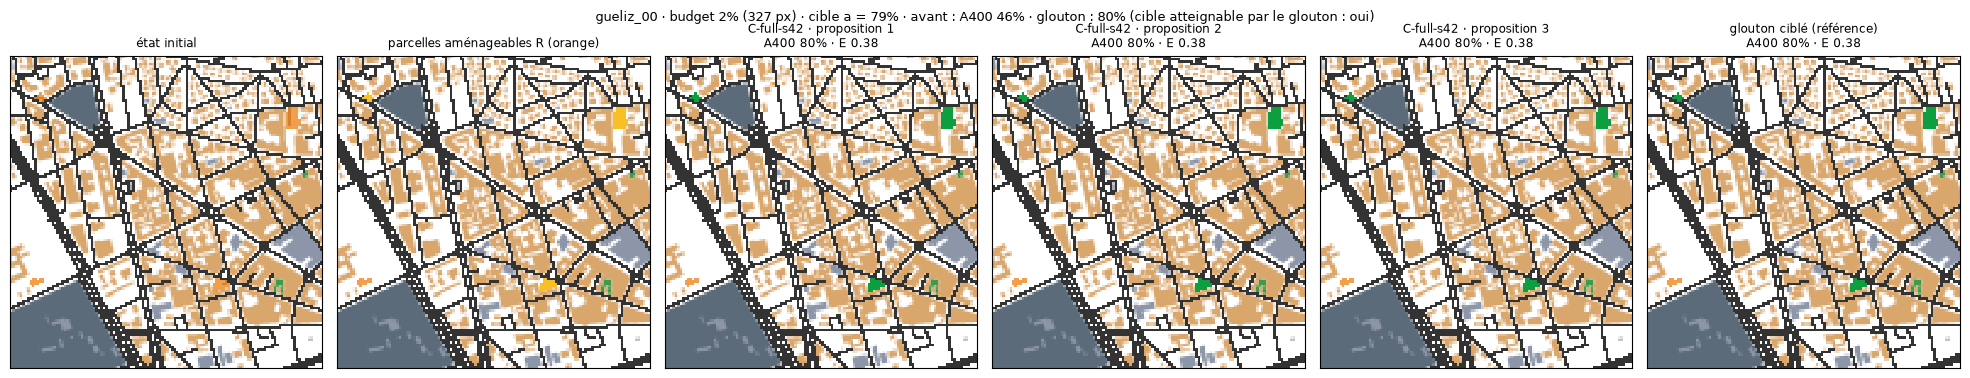

In [3]:
row = tiles.set_index("tile_id").loc["gueliz_00"]
s = demo.run_scenario(cfg, model, row["pair_file"], 0.02, float(row["greedy_0.02"]) - 0.005, n=3)
demo.plot_scenario(s)
demo.scenario_table(s)

Sur les tuiles réelles, il y a peu de parcelles aménageables (ici quelques-unes) : toutes
les méthodes convergent vers la même solution, et la diversité est nulle. C'est la limite
principale du test réel (voir `docs/evaluation.md`).

## 3. Une tuile synthétique : plusieurs solutions possibles

diversité des propositions : 0.03


,option,A400,ΔA400,E,V,surface ajoutée (m²),valide,|â − a|
0,état initial,0.731,0.000,0.445,0.013,0.0,True,0.219
1,C-full-s42 · proposition 1,0.977,0.246,0.925,0.033,20928.0,True,0.027
2,C-full-s42 · proposition 2,0.977,0.246,0.925,0.033,20928.0,True,0.027
3,C-full-s42 · proposition 3,0.963,0.232,0.855,0.033,20864.0,True,0.013
4,glouton ciblé (référence),0.977,0.246,0.944,0.025,12224.0,True,0.027


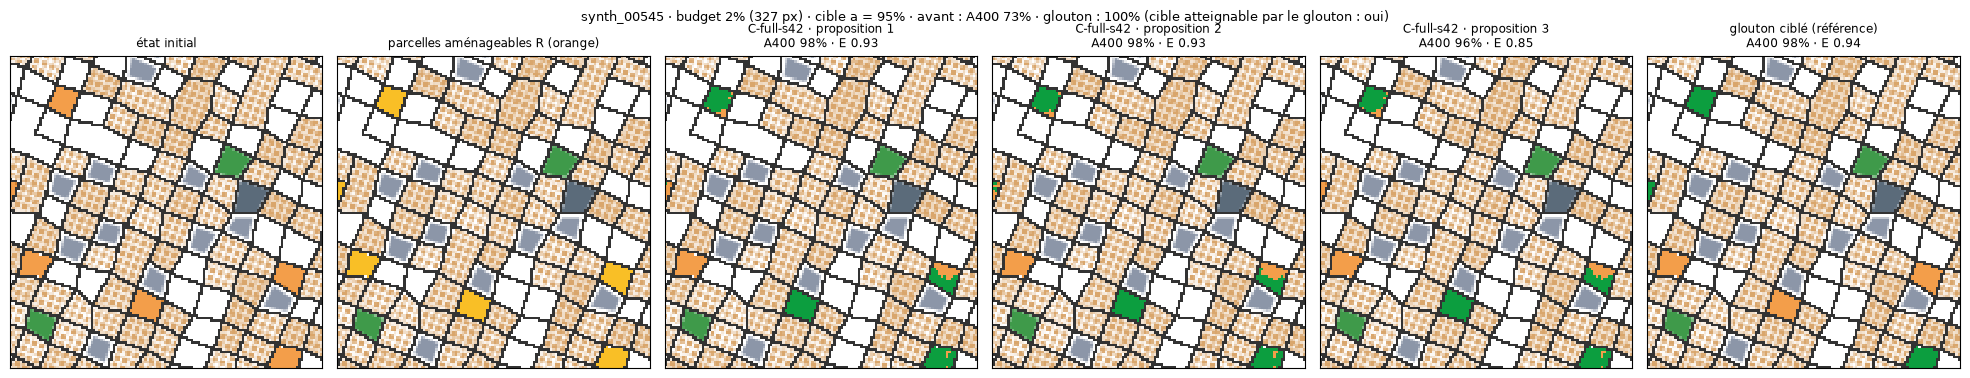

In [4]:
row = tiles.set_index("tile_id").loc["synth_00545"]
s = demo.run_scenario(cfg, model, row["pair_file"], 0.02, 0.95, n=3, seed=1)
demo.plot_scenario(s)
print("diversité des propositions :", round(demo.diversity(s), 3))
demo.scenario_table(s)

## 4. Une cible inatteignable

On demande plus que ce que le glouton atteint avec ce budget. Le modèle s'en approche au
mieux **sans jamais violer** les contraintes (projection) ; |â − a| est rapporté tel quel.

In [5]:
row = tiles.set_index("tile_id").loc["synth_00545"]
s = demo.run_scenario(cfg, model, row["pair_file"], 0.01, 1.0, n=3)
print("cible atteignable par le glouton :", "oui" if s.reachable else "non",
      f"(glouton : {s.greedy_max:.1%})")
demo.scenario_table(s)

cible atteignable par le glouton : non (glouton : 97.7%)


,option,A400,ΔA400,E,V,surface ajoutée (m²),valide,|â − a|
0,état initial,0.731,0.000,0.445,0.013,0.0,True,0.269
1,C-full-s42 · proposition 1,0.961,0.230,0.845,0.019,6400.0,True,0.039
2,C-full-s42 · proposition 2,0.961,0.230,0.845,0.019,6336.0,True,0.039
3,C-full-s42 · proposition 3,0.961,0.230,0.845,0.019,6784.0,True,0.039
4,glouton ciblé (référence),0.977,0.246,0.944,0.023,10432.0,True,0.023


## 5. Pourquoi la projection compte : variante A (sans projection)

Même tuile, même budget et même cible avec le modèle **A**. Ses sorties brutes ne passent pas
par l'opérateur de projection : la colonne « valide » montre les violations éventuelles
(ajouts hors des parcelles autorisées, au-delà du budget ou détachés du réseau).

,option,A400,ΔA400,E,V,surface ajoutée (m²),valide,|â − a|
0,état initial,0.288,0.000,0.239,0.009,0.0,True,0.112
1,A-full-s42 · proposition 1,0.384,0.096,0.165,0.013,3776.0,False,0.016
2,A-full-s42 · proposition 2,0.384,0.096,0.165,0.013,4032.0,False,0.016
3,A-full-s42 · proposition 3,0.378,0.091,0.165,0.012,3200.0,False,0.022
4,glouton ciblé (référence),0.384,0.096,0.165,0.013,3904.0,True,0.016


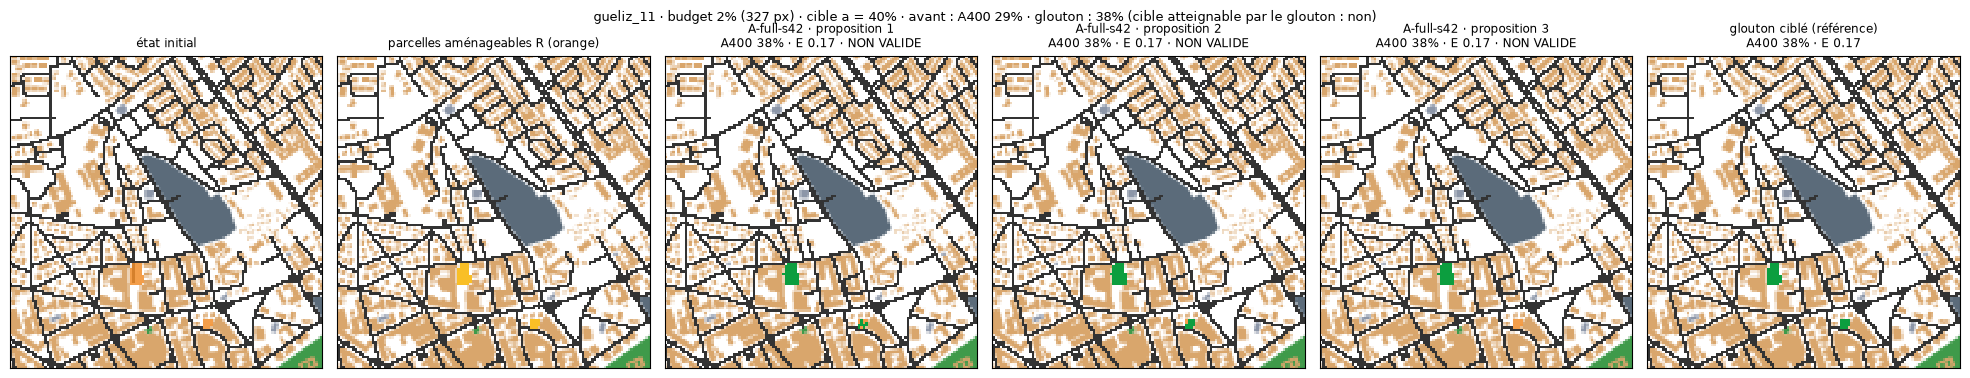

In [6]:
model_a = next(r for r in runs if r.variant == "A" and r.seed == model.seed)
row = tiles.set_index("tile_id").loc["gueliz_11"]
s = demo.run_scenario(cfg, model_a, row["pair_file"], 0.02, 0.40, n=3)
demo.plot_scenario(s)
demo.scenario_table(s)

## 6. La cible a pilote-t-elle le résultat ?

On fait varier la cible a sur une même tuile, avec le même budget. Si le modèle utilisait a,
l'A400 obtenu suivrait la diagonale grise, comme le fait (par paliers) le glouton ciblé.

,cible a,A400 modèle (moyenne),A400 glouton ciblé
0,0.75,0.996,0.793
1,0.80,0.996,0.942
2,0.85,0.996,0.942
3,0.90,0.996,0.942
4,0.95,0.996,0.977
5,1.00,0.996,0.996


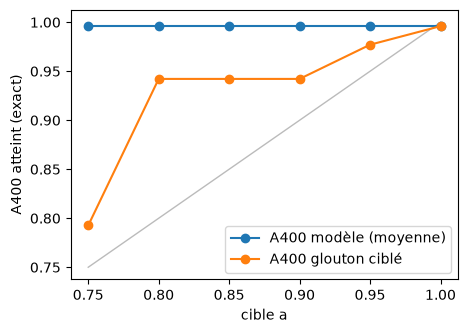

In [7]:
import matplotlib.pyplot as plt

row = tiles.set_index("tile_id").loc["synth_00545"]
targets = [0.75, 0.80, 0.85, 0.90, 0.95, 1.00]
rows = []
for a in targets:
    sc = demo.run_scenario(cfg, model, row["pair_file"], 0.03, a, n=3)
    t = demo.scenario_table(sc)
    gen = t[t["option"].str.contains("proposition")]
    rows.append({"cible a": a, "A400 modèle (moyenne)": gen["A400"].mean(),
                 "A400 glouton ciblé": t["A400"].iloc[-1]})
sweep = pd.DataFrame(rows)
ax = sweep.plot(x="cible a", marker="o", figsize=(5, 3.5))
ax.plot([0.75, 1], [0.75, 1], color="#bbb", lw=1, zorder=0)
ax.set_ylabel("A400 atteint (exact)")
sweep

**Non.** Le modèle donne le même A400 quelle que soit la cible : il **maximise l'accès
avec le budget** et ignore a. Ce n'est pas propre à cette tuile : le test de réponse à la
condition (`happycity evaluate`, `docs/evaluation.md`) donne une pente ≈ 0 pour A, B et C
sur les 3 graines. Cause : les paires d'entraînement saturent toujours le budget, si bien
que a n'apporte aucune information de plus que b.

## 7. Résultats d'ensemble (phase 6)

Rappel du tableau principal sur le **test synthétique** (moyenne ± écart-type sur 3 graines
pour A, B, C). Détails et limites : `docs/evaluation.md`.

In [8]:
evaluation = Path(cfg.paths.experiments_dir) / "evaluation"
summary = pd.read_csv(evaluation / "summary_test_synth.csv")
summary[["méthode", "graines", "|â−a| atteignable", "|â−a| non atteignable", "A400 après",
         "E après", "valide", "diversité"]]

,méthode,graines,|â−a| atteignable,|â−a| non atteignable,A400 après,E après,valide,diversité
0,A,3,0.037 ± 0.003,0.114 ± 0.010,86.5 ± 0.6 %,0.721 ± 0.007,16.0 ± 10.6 %,0.161 ± 0.058
1,B,3,0.039 ± 0.004,0.104 ± 0.011,86.9 ± 1.1 %,0.721 ± 0.019,18.6 ± 3.8 %,0.110 ± 0.009
2,C,3,0.034 ± 0.002,0.096 ± 0.004,87.7 ± 0.5 %,0.738 ± 0.008,100.0 ± 0.0 %,0.039 ± 0.003
3,C – sans attention,1,0.034,0.096,87.5 %,0.729,100.0 %,0.052
4,C – sans diversité,1,0.030,0.082,88.9 %,0.747,100.0 %,0.033
5,C – sans modulation,1,0.035,0.086,88.7 %,0.754,100.0 %,0.059
6,C – sans projection,1,0.033,0.103,87.2 %,0.735,33.2 %,0.085
7,aléatoire,—,0.071,0.164,81.2 %,0.608,100.0 %,0.585
8,glouton,—,0.017,0.074,89.7 %,0.788,100.0 %,—
9,glouton ciblé,—,0.013,0.075,89.3 %,0.781,100.0 %,—


**À retenir**
- Les modèles placent bien les espaces verts (A400 proche du glouton, 2 fois moins d'écart
  que l'aléatoire) mais **ignorent la cible a** : ils maximisent l'accès avec le budget ;
- **C** est le seul valide à 100 % (grâce à la projection), au prix d'une **faible
  diversité** ;
- Ces indicateurs décrivent l'**accès piéton** et la **végétation**, pas le bonheur des
  habitants.